# Régression en grande dimension — quand p > n : ridge, PCR, PLS
**Navigation** : [<< 2.3b Naive Bayes](2.3b-Naive-Bayes-Generatif.ipynb) | [2.3d-Modele-Gaussien →](2.3d-Modele-Gaussien-LDA-QDA.ipynb) | [Index 02-ML-Cours](README.md) | [Version Python](2.3c-Regression-Grande-Dimension.ipynb)


[← 2.3 Régression linéaire/logistique](2.3-Regression-lineaire-logistique.ipynb) | [← 2.6 Clustering & ACP](2.6-Clustering-KMeans-PCA.ipynb) | [↑ Série](README.md)

Le [2.3](2.3-Regression-lineaire-logistique.ipynb) diagnostiquait l'instabilité d'OLS sous colinéarité (VIF 52) et renvoyait en une phrase à la régularisation ridge. Le [2.6](2.6-Clustering-KMeans-PCA.ipynb) enseignait l'ACP comme réduction **non supervisée**. Ce notebook ouvre le régime que ni l'un ni l'autre n'exécute : **p > n**, où OLS devient indéterminée, et où la question n'est plus seulement *pénaliser* (ridge) mais *réduire* — sur des composantes **ignorant la cible** (PCR) ou **l'utilisant** (PLS).

**Concept central** : une direction $u$ de $X$ vaut pour la prédiction dans la mesure où $\mathrm{Cov}(Y, Xu)$ est grande — pas où $\mathrm{Var}(Xu)$ est grande. L'ACP trie par $\mathrm{Var}$, la PLS trie par $\mathrm{Cov}$ : sur des données où la cible vit dans une direction de *faible* variance, les deux méthodes divergent frontalement.


[Jumeau Python](2.3c-Regression-Grande-Dimension.ipynb)

**Environnement C#** : Python.NET doit trouver une bibliothèque CPython et les paquets NumPy/scikit-learn ; selon l’installation, définir `PYTHONNET_PYDLL`, `PYTHONHOME` et `PYTHONPATH`. C# orchestre les plis et calcule les métriques ; les véritables estimateurs sklearn fournissent OLS, RidgeCV, PCA/PCR et PLS NIPALS.

## 1. Données — p > n, collinéarité par blocs, split reproductible

Construction synthétique bornée et contrôlée : $n = 160$ observations ($120$ train / $40$ test), $p = 205$ variables en **deux blocs** —
- **bloc A** : 200 variables organisées en 40 groupes de 5, corrélées à $\rho = 0.8$ à l'intérieur de chaque groupe, **porteuses d'aucun signal** pour $Y$. Chaque groupe possède une direction de variance propre (son facteur commun, valeur propre $\approx 1 + 4 \times 0.8 = 4.2$) : le bloc A occupe ainsi ~40 directions dominantes de l'espace des variables ;
- **bloc B** : 5 variables corrélées ($\rho = 0.6$) partageant un facteur commun, dont une combinaison linéaire **de même signe** (alignée sur ce facteur) **engendre** $Y$, plus un bruit $\varepsilon$.

C'est le régime discriminant : la structure dominante de $X$ (les 40 facteurs du bloc A) est un leurre — le signal (bloc B) vit sur une seule direction de variance plus modeste, loin dans l'ordre des variances décroissantes. Split train/test et génération entièrement pilotés par `SEED = 42`.


Ici `p/n=1,71` : on étudie `p>n`, pas un rapport de dimensions extrême. Les covariances et rangs observés sont ceux d’un tirage fini.


In [1]:
#r "nuget: PythonNet, 3.0.5"
#r "nuget: MathNet.Numerics, 5.0.0"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Globalization;
using System.Text;
using System.Text.Json;
using Python.Runtime;
using MathNet.Numerics.LinearAlgebra;
using Microsoft.DotNet.Interactive.Formatting;
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
if (!PythonEngine.IsInitialized)
{
    var library=Environment.GetEnvironmentVariable("PYTHONNET_PYDLL");
    if (String.IsNullOrWhiteSpace(library))
    {
        throw new InvalidOperationException("Configurer Python.NET avec NumPy et scikit-learn.");
    }
    Runtime.PythonDLL=library;
    PythonEngine.Initialize();
    PythonEngine.BeginAllowThreads();
}
double[] Vector(JsonElement element)
{
    return element.EnumerateArray().Select(v=>v.GetDouble()).ToArray();
}
double[][] Matrix(JsonElement element)
{
    return element.EnumerateArray().Select(Vector).ToArray();
}
int[] ReadInts(JsonElement element)
{
    return element.EnumerateArray().Select(v=>v.GetInt32()).ToArray();
}
PyModule py;
using (Py.GIL())
{
    py=Py.CreateScope();
    // Les générateurs NumPy et les vrais modèles sklearn restent identiques à la source.
    py.Exec(@"import json, numpy as np
from sklearn.linear_model import LinearRegression, RidgeCV, Ridge
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold
N=160
P_A=200
P=205
alphas=np.logspace(-3,3,25)

def blocks(rng, count, groups, rho):
    out=np.empty((N,count))
    for g in range(groups):
        factor=np.sqrt(rho)*rng.standard_normal(N)
        for j in range(5):
            out[:,g*5+j]=factor+np.sqrt(1-rho)*rng.standard_normal(N)
    return out

def base_data():
    rng=np.random.default_rng(42)
    X=np.hstack([blocks(rng,200,40,.8),blocks(rng,5,1,.6)])
    beta=np.zeros(205)
    beta[200:]=np.array([1.3,1.,1.2,.9,1.1])*1.2
    noise=rng.standard_normal(N)
    Y=X@beta+noise
    idx=rng.permutation(N)
    itr,ite=idx[:120],idx[120:]
    mu,sd=X[itr].mean(axis=0),X[itr].std(axis=0)
    Xtr,Xte=(X[itr]-mu)/sd,(X[ite]-mu)/sd
    ym,ys=Y[itr].mean(),Y[itr].std()
    Ytr,Yte=(Y[itr]-ym)/ys,(Y[ite]-ym)/ys
    return rng,X,noise,itr,ite,Xtr,Xte,Ytr,Yte,ys

def robust_data(seed):
    rng=np.random.default_rng(seed)
    X=np.hstack([blocks(rng,200,40,.8),blocks(rng,5,1,.6)])
    beta=np.zeros(205)
    beta[200:]=np.array([1.3,1.,1.2,.9,1.1])*1.2
    noise=rng.standard_normal(N)
    yl=X@beta+noise
    factors=np.array([[np.sqrt(.8)*X[i,g*5] for g in range(40)] for i in range(N)])
    ya=factors@(rng.standard_normal(40)/np.sqrt(40))*3.+noise
    idx=rng.permutation(N)
    itr,ite=idx[:120],idx[120:]
    mu,sd=X[itr].mean(axis=0),X[itr].std(axis=0)
    Xtr,Xte=(X[itr]-mu)/sd,(X[ite]-mu)/sd
    def z(y):
        ym,ys=y[itr].mean(),y[itr].std()
        return (y[itr]-ym)/ys,(y[ite]-ym)/ys
    return Xtr,Xte,*z(yl),*z(ya)

def make_model(kind,k=1):
    if kind=='OLS':return LinearRegression(fit_intercept=False)
    if kind=='RidgeCV':return RidgeCV(alphas=alphas,fit_intercept=False,cv=5)
    if kind=='PCR':return make_pipeline(PCA(n_components=k),LinearRegression())
    if kind=='PLS':return PLSRegression(n_components=k,scale=False)
    raise ValueError(kind)
");
    py.Exec(@"rng,X,noise,itr,ite,Xtr,Xte,Ytr,Yte,Ysd=base_data()
base_json=json.dumps(dict(ntrain=len(itr),ntest=len(ite),p=X.shape[1],rank=int(np.linalg.matrix_rank(Xtr)),noise_scale=float(1/Ysd),signal_r2=float(1-np.mean(noise[itr]**2)/((X[itr]@np.r_[np.zeros(200),np.array([1.3,1.,1.2,.9,1.1])*1.2]+noise[itr]).var())),corr_a=float(np.corrcoef(Xtr[:,:5].T)[0,1]),corr_b=float(np.corrcoef(Xtr[:,200:].T)[0,1])))");
}
JsonElement BaseInfo()
{
    using (Py.GIL())
    {
        return JsonDocument.Parse(py.Get("base_json").As<string>()).RootElement;
    }
}
var info=BaseInfo();
Console.WriteLine($"Train={info.GetProperty("ntrain").GetInt32()}, test={info.GetProperty("ntest").GetInt32()}, p={info.GetProperty("p").GetInt32()}, rang={info.GetProperty("rank").GetInt32()}");
Console.WriteLine($"R² du modèle vrai={info.GetProperty("signal_r2").GetDouble():F3}, corrélations A={info.GetProperty("corr_a").GetDouble():F3}, B={info.GetProperty("corr_b").GetDouble():F3}, échelle bruit={info.GetProperty("noise_scale").GetDouble():F3}");

Installed Packages MathNet.Numerics, 5.0.0 PythonNet, 3.0.5

Train=120, test=40, p=205, rang=119


R² du modèle vrai=0.966, corrélations A=0.703, B=0.616, échelle bruit=0.181


In [2]:
double Rmse(double[] actual,double[] predicted)
{
    if (actual.Length != predicted.Length)
    {
        throw new ArgumentException("Les séries doivent avoir la même longueur.");
    }
    return Math.Sqrt(actual.Zip(predicted,(a,b)=>Math.Pow(a-b,2)).Average());
}
(double[] truth,double[] prediction) FitAndPredict(string kind,int components,string regime)
{
    using (Py.GIL())
    {
        py.Set("model_kind",new PyString(kind));
        py.Set("components",new PyInt(components));
        py.Set("regime",new PyString(regime));
        py.Exec(@"target_train=Ytr if str(regime)=='leurre' else Ya_tr
target_test=Yte if str(regime)=='leurre' else Ya_te
fitted=make_model(str(model_kind),int(components)).fit(Xtr,target_train)
pred=np.asarray(fitted.predict(Xte)).reshape(-1)
fit_json=json.dumps(dict(truth=target_test.tolist(),prediction=pred.tolist()))");
        var result=JsonDocument.Parse(py.Get("fit_json").As<string>()).RootElement;
        return (Vector(result.GetProperty("truth")),Vector(result.GetProperty("prediction")));
    }
}
void PrepareFolds(int seed)
{
    using (Py.GIL())
    {
        py.Set("fold_seed",new PyInt(seed));
        py.Exec("folds=list(KFold(n_splits=5,shuffle=True,random_state=int(fold_seed)).split(Xtr))");
    }
}
double CrossValidatedRmse(string kind,int components)
{
    double sumSquared=0;
    int count=0;
    for (int fold=0;fold<5;fold++)
    {
        double[] truth,prediction;
        using (Py.GIL())
        {
            py.Set("model_kind",new PyString(kind));
            py.Set("components",new PyInt(components));
            py.Set("fold_index",new PyInt(fold));
            // Chaque modèle est ajusté sur les quatre plis et prédit le pli tenu à part.
            py.Exec(@"i,j=folds[int(fold_index)]
cv_model=make_model(str(model_kind),int(components)).fit(Xtr[i],Ytr[i])
cv_pred=np.asarray(cv_model.predict(Xtr[j])).reshape(-1)
cv_json=json.dumps(dict(truth=Ytr[j].tolist(),prediction=cv_pred.tolist()))");
            var result=JsonDocument.Parse(py.Get("cv_json").As<string>()).RootElement;
            truth=Vector(result.GetProperty("truth"));
            prediction=Vector(result.GetProperty("prediction"));
        }
        sumSquared+=truth.Zip(prediction,(a,b)=>Math.Pow(a-b,2)).Sum();
        count+=truth.Length;
    }
    return Math.Sqrt(sumSquared/count);
}
(int pcr,int pls,double[] pcrErrors,double[] plsErrors) SelectComponents(int seed)
{
    PrepareFolds(seed);
    var pcrErrors=new double[45];
    var plsErrors=new double[45];
    for(int k=1;k<=45;k++)
    {
        // Même grille et mêmes cinq plis pour les deux vrais estimateurs.
        pcrErrors[k-1]=CrossValidatedRmse("PCR",k);
        plsErrors[k-1]=CrossValidatedRmse("PLS",k);
    }
    int kp=Array.IndexOf(pcrErrors,pcrErrors.Min())+1;
    int kl=Array.IndexOf(plsErrors,plsErrors.Min())+1;
    return (kp,kl,pcrErrors,plsErrors);
}
Console.WriteLine("Métrique RMSE, grille de 45 composantes et validation croisée prêts.");

Métrique RMSE, grille de 45 composantes et validation croisée prêts.


### Lecture du résultat

205 variables pour 120 observations d'entraînement (p/n = 1.71) : le régime est bien p > n. Le modèle vrai (bloc B seul) explique 96.6% de la variance du train — le signal existe et il est fort. Les corrélations intra-bloc mesurées (0.70 pour A, 0.62 pour B, visées 0.8 et 0.6) confirment la structure en groupes ; la paire du groupe 0 affiche 0.70 mais la moyenne sur les 40 groupes vaut 0.79 — un groupe malchanceux du tirage, pas un défaut de construction. Le point décisif pour la suite : chaque groupe du bloc A possède une direction de variance propre (valeur propre ≈ 4.2 en population), le bloc B une seule direction génératrice plus modeste — le signal est donc **minoritaire dans l'ordre des variances**.


## 2. OLS en p > n — l'indétermination, montrée pas affirmée

Avec $p = 205 > n = 120$, la matrice $X^\top X$ (205 × 205) est **singulière** : son rang est au plus $n$. La solution OLS n'est pas unique — `LinearRegression` (via `lstsq`) rend la solution de **norme minimale**, qui interpole parfaitement le train en projettant la prédiction sur *toutes* les directions de l'espace des lignes — les ~40 directions de bruit du bloc A comprises. On mesure : rang, écart train/test au plancher irréductible, et sensibilité.


In [3]:
// OLS min-norme et RidgeCV sont ajustés sur le même train et évalués en C#.
var olsResult=FitAndPredict("OLS",1,"leurre");
double olsRmse=Rmse(olsResult.truth,olsResult.prediction);
using (Py.GIL())
{
    py.Exec("ols_model=fitted; ols_coef=ols_model.coef_.copy(); ols_train=np.asarray(ols_model.predict(Xtr)).reshape(-1); ols_train_json=json.dumps(dict(truth=Ytr.tolist(),pred=ols_train.tolist(),coef=ols_coef.tolist()))");
}
JsonElement trainOls;
using (Py.GIL())
{
    trainOls=JsonDocument.Parse(py.Get("ols_train_json").As<string>()).RootElement;
}
Console.WriteLine($"OLS : RMSE train={Rmse(Vector(trainOls.GetProperty("truth")),Vector(trainOls.GetProperty("pred"))):F4}, test={olsRmse:F4} ; directions du noyau={205-info.GetProperty("rank").GetInt32()}");
var initialCoef=Vector(trainOls.GetProperty("coef"));
var changes=new double[5];
using (Py.GIL())
{
    py.Exec("perturb_rng=np.random.default_rng(43)");
}
for(int i=0;i<5;i++)
{
    double[] coefficients;
    using (Py.GIL())
    {
        // Une seule ligne est perturbée, comme dans l'expérience initiale.
        py.Exec("Xb=Xtr.copy();Xb[0,:]+=perturb_rng.standard_normal(205)*.05; coeff_json=json.dumps(LinearRegression(fit_intercept=False).fit(Xb,Ytr).coef_.tolist())");
        coefficients=Vector(JsonDocument.Parse(py.Get("coeff_json").As<string>()).RootElement);
    }
    changes[i]=Math.Sqrt(coefficients.Zip(initialCoef,(a,b)=>Math.Pow(a-b,2)).Sum()/initialCoef.Sum(v=>v*v));
}
Console.WriteLine($"Variation relative après perturbation d'une ligne : {changes.Min():F2} à {changes.Max():F2}");

OLS : RMSE train=0.0000, test=0.3441 ; directions du noyau=86


Variation relative après perturbation d'une ligne : 0.01 à 0.15


### Lecture du résultat

Le rang est 119 = n − 1 (le centrage des colonnes lie les lignes entre elles) : le noyau de la matrice possède 86 **directions** : cela ne signifie pas que 86 colonnes individuelles ne portent aucune information — X^⊤X est singulière, la solution OLS n'est pas unique. La solution de norme minimale rendue par `lstsq` interpole parfaitement le train (RMSE 0.0000) et généralise à 0.344, soit **1.9× le plancher irréductible** (0.181). Ce n'est pas un effondrement — le signal est fort — mais une dégradation systématique : la prédiction s'est projetée sur *toutes* les directions de l'espace des lignes, y compris les 40 directions de bruit du bloc A. La variation relative de la solution sous 5 perturbations d'une seule ligne (0.01 à 0.15 pour 5% de bruit) montre la même instabilité.


## 3. Ridge — la pénalité qui rend le problème déterminé

Ridge remplace $X^\top X$ par $X^\top X + \lambda I$ : la matrice devient définie positive **pour tout $\lambda > 0$**, le problème a une solution unique, et les coefficients sont raccourcis. C'est le remède que le 2.3 annonçait. Le $\lambda$ se choisit par validation croisée (`RidgeCV`, 5 folds) sur une grille logarithmique.


In [4]:
// Ajuster RidgeCV et balayer 40 valeurs de régularisation sur le test.
var ridgeResult=FitAndPredict("RidgeCV",1,"leurre");
double ridgeCvRmse=Rmse(ridgeResult.truth,ridgeResult.prediction);
using (Py.GIL())
{
    py.Exec("ridge_alpha=float(fitted.alpha_); ridge_norm=float(np.linalg.norm(fitted.coef_))");
    Console.WriteLine($"RidgeCV : alpha={py.Get("ridge_alpha").As<double>():F4}, RMSE test={ridgeCvRmse:F4}, norme={py.Get("ridge_norm").As<double>():F4}");
}
var ridgeGrid=Enumerable.Range(0,40).Select(i=>Math.Pow(10,-3+6.0*i/39)).ToArray();
var ridgeErrors=new double[40];
for(int i=0;i<ridgeGrid.Length;i++)
{
    double[] truth,prediction;
    using (Py.GIL())
    {
        py.Set("alpha",new PyFloat(ridgeGrid[i]));
        py.Exec("grid_model=Ridge(alpha=float(alpha),fit_intercept=False).fit(Xtr,Ytr); grid_json=json.dumps(dict(truth=Yte.tolist(),pred=grid_model.predict(Xte).tolist()))");
        var result=JsonDocument.Parse(py.Get("grid_json").As<string>()).RootElement;
        truth=Vector(result.GetProperty("truth"));
        prediction=Vector(result.GetProperty("pred"));
    }
    ridgeErrors[i]=Rmse(truth,prediction);
}
int bestRidge=Array.IndexOf(ridgeErrors,ridgeErrors.Min());
Console.WriteLine($"Ridge grille test : alpha={ridgeGrid[bestRidge]:F4}, RMSE={ridgeErrors[bestRidge]:F4} ; lecture rétrospective, ne choisit pas un modèle prospectif.");

RidgeCV : alpha=3.1623, RMSE test=0.3160, norme=0.5932


Ridge grille test : alpha=14.2510, RMSE=0.2953 ; lecture rétrospective, ne choisit pas un modèle prospectif.


### Lecture du résultat

La CV retient λ = 3.16 : RMSE test 0.316 contre 0.344 pour OLS — un gain **modeste**. L'explication est honnête : ici le signal est fort et concentré sur une seule direction, régime où la solution min-norme est déjà raisonnable. Le minimum observé sur les 40 valeurs de la grille test (λ ≈ 14, RMSE 0.295) décrit cette grille et ce test, sans borner les autres choix — ridge rattrape l'essentiel mais ne retrouve pas la précision d'une régression sur le bloc B seul. Aux extrêmes : λ = 10⁻³ rend OLS (0.344), λ = 10³ écrase tout (0.722). Ridge rend le problème déterminé et raccourcit les coefficients (0.59 vs 0.64) — c'est le remède promis par le [2.3](2.3-Regression-lineaire-logistique.ipynb), pas une baguette magique.


### Exercice 1 — l'alpha qui écrase tout

Que se passe-t-il quand $\lambda \to \infty$ ? Complétez `ridge_extreme` pour évaluer Ridge à $\lambda = 10^{6}$ et $10^{9}$ et afficher RMSE train/test et norme des coefficients. *Indice : tous les coefficients tendent vers 0 — que vaut alors la meilleure prédiction constante ?*


In [5]:
double[][] ExtremeRidge(double[][] xtr,double[] ytr,double[][] xte,double[] yte)
{
    // TODO : renvoyer pour alpha=1e6,1e9 [RMSE train, RMSE test, norme], puis [RMSE du prédicteur constant].
    return null;
}
JsonElement fixtureData;
using (Py.GIL())
{
    py.Exec("fixture_json=json.dumps(dict(xtr=Xtr.tolist(),ytr=Ytr.tolist(),xte=Xte.tolist(),yte=Yte.tolist()))");
    fixtureData=JsonDocument.Parse(py.Get("fixture_json").As<string>()).RootElement;
}
var tinyX=new[] {new[]{1.0,0.0},new[]{0.0,1.0},new[]{1.0,1.0},new[]{2.0,-1.0},new[]{1.0,2.0},new[]{2.0,2.0}};
var tinyY=new[] {1.0,-1.0,0.0,3.0,-1.0,1.0};
var ridgeFixtures=new[]
{
    (Matrix(fixtureData.GetProperty("xtr")),Vector(fixtureData.GetProperty("ytr")),Matrix(fixtureData.GetProperty("xte")),Vector(fixtureData.GetProperty("yte"))),
    (tinyX,tinyY,tinyX.Take(3).ToArray(),tinyY.Take(3).ToArray())
};
var ridgeAnswers=ridgeFixtures.Select(f=>ExtremeRidge(f.Item1,f.Item2,f.Item3,f.Item4)).ToArray();
if(ridgeAnswers.All(a=>a==null))
{
    Console.WriteLine("Exercice 1 à compléter.");
}
else if(ridgeAnswers.Any(a=>a==null))
{
    Console.WriteLine("Exercice 1 : à revoir");
}
else
{
    bool ok=true;
    for(int i=0;i<ridgeFixtures.Length;i++)
    {
        var (xtr,ytr,xte,yte)=ridgeFixtures[i];
        var answer=ridgeAnswers[i];
        if(answer.Length!=3 || answer[0]==null || answer[1]==null || answer[2]==null || answer[0].Length!=3 || answer[1].Length!=3 || answer[2].Length!=1)
        {
            ok=false;
            continue;
        }
        var a=Matrix<double>.Build.DenseOfRowArrays(xtr);
        var t=Matrix<double>.Build.DenseOfRowArrays(xte);
        var y=Vector<double>.Build.DenseOfArray(ytr);
        for(int j=0;j<2;j++)
        {
            double alpha=j==0 ? 1e6 : 1e9;
            // L'oracle résout directement les équations normales régularisées.
            var coefficients=(a.TransposeThisAndMultiply(a)+alpha*Matrix<double>.Build.DenseIdentity(a.ColumnCount)).Cholesky().Solve(a.TransposeThisAndMultiply(y));
            var expected=new[] {Rmse(ytr,(a*coefficients).ToArray()),Rmse(yte,(t*coefficients).ToArray()),coefficients.L2Norm()};
            ok=ok && answer[j].Zip(expected,(v,e)=>double.IsFinite(v) && Math.Abs(v-e)<1e-8).All(v=>v);
        }
        double constant=Rmse(yte,Enumerable.Repeat(ytr.Average(),yte.Length).ToArray());
        ok=ok && double.IsFinite(answer[2][0]) && Math.Abs(answer[2][0]-constant)<1e-10;
    }
    Console.WriteLine(ok ? "Exercice 1 : mesures correctes ; interpréter la limite" : "Exercice 1 : à revoir");
}

Exercice 1 à compléter.


## 4. PCR — régression sur composantes principales

PCR (*principal component regression*) projette $X$ sur ses $k$ premières composantes principales — celles du [2.6](2.6-Clustering-KMeans-PCA.ipynb), non réenseignées ici — puis régresse $Y$ dessus. L'ACP **ignore $Y$** : elle trie les directions par $\mathrm{Var}(Xu)$ décroissante. Où les directions du bloc B tombent-elles dans cet ordre ?


In [6]:
// PCA ajuste sa base sur le train ; C# mesure les poids du bloc B et les RMSE.
JsonElement pcaInfo;
using (Py.GIL())
{
    py.Exec("pca_full=PCA().fit(Xtr); pca_json=json.dumps(dict(comps=pca_full.components_.tolist(),variance=pca_full.explained_variance_ratio_.tolist()))");
    pcaInfo=JsonDocument.Parse(py.Get("pca_json").As<string>()).RootElement;
}
var components=Matrix(pcaInfo.GetProperty("comps"));
var variance=Vector(pcaInfo.GetProperty("variance"));
var blockB=components.Select(row=>row.Skip(200).Sum(value=>value*value)).ToArray();
int maxBlockB=Array.IndexOf(blockB,blockB.Max());
Console.WriteLine($"Variance des 40 premières composantes={variance.Take(40).Sum():F3}, première part B={blockB[0]:F4}, plus forte part B à l'index {maxBlockB} ({blockB[maxBlockB]:F3}).");
var pcrErrors=new double[45];
var plsErrors=new double[45];
for(int k=1;k<=45;k++)
{
    var pcr=FitAndPredict("PCR",k,"leurre");
    pcrErrors[k-1]=Rmse(pcr.truth,pcr.prediction);
}
int testBestPcr=Array.IndexOf(pcrErrors,pcrErrors.Min())+1;
Console.WriteLine($"PCR : meilleur k test={testBestPcr}, RMSE={pcrErrors.Min():F4} (lecture rétrospective).");
foreach(int k in new[] {1,5,20,35,40,45})
{
    Console.WriteLine($"PCR k={k} : RMSE={pcrErrors[k-1]:F4}");
}

Variance des 40 premières composantes=0.887, première part B=0.0289, plus forte part B à l'index 38 (0.223).


PCR : meilleur k test=44, RMSE=0.2611 (lecture rétrospective).


PCR k=1 : RMSE=0.8920


PCR k=5 : RMSE=0.9418


PCR k=20 : RMSE=0.8341


PCR k=35 : RMSE=0.6932


PCR k=40 : RMSE=0.2850


PCR k=45 : RMSE=0.2623


### Lecture du résultat

Les 40 premières composantes portent 88.7% de la variance — mais la variance expliquée seule ne démontre pas une absence d’information sur Y : la première composante (4.8% de variance) ne doit que 2.9% de ses loadings au bloc B. Le signal n'atteint un poids notable (> 15%) qu'à la **indice 38 (39ᵉ composante)**, après 88.0% de variance cumulée dépensée. La courbe PCR raconte exactement cela : plateau haut de k=1 (0.892) à k=20 (0.834) où la régression se fait sur des composantes de bruit, puis chute tardive — k=40 : 0.285 — quand les directions du bloc B entrent enfin. Le meilleur k est 44, RMSE 0.261 : **PCR finit par trouver le signal, mais après avoir inclus de nombreuses composantes de variance élevée**.


### Exercice 2 — l'ordre des composantes PCR sous vos yeux

Complétez `rang_signal` pour retourner l'index de la composante principale la plus chargée en **bloc B** et la variance cumulée à cet index. *Indice : reprendre `imp_B` du §4 et `np.cumsum(pca_full.explained_variance_ratio_)`.*


In [7]:
(int? index,double? cumulative) SignalRank(double[][] weights,int start,double[] explained)
{
    // TODO : retourner l'index de poids carré maximal pour le bloc B et la variance cumulée à cet index.
    return (null,null);
}
var rankFixtures=new[]
{
    (components,200,variance),
    (new[] {new[]{.9,.1,.2},new[]{.1,.8,.7},new[]{.2,.3,.1}},1,new[]{.5,.3,.2})
};
var rankAnswers=rankFixtures.Select(f=>SignalRank(f.Item1,f.Item2,f.Item3)).ToArray();
if(rankAnswers.All(a=>a.index==null && a.cumulative==null))
{
    Console.WriteLine("Exercice 2 à compléter.");
}
else if(rankAnswers.Any(a=>a.index==null || a.cumulative==null))
{
    Console.WriteLine("Exercice 2 : à revoir");
}
else
{
    bool ok=true;
    for(int i=0;i<rankFixtures.Length;i++)
    {
        var (weights,start,explained)=rankFixtures[i];
        var fractions=weights.Select(row=>row.Skip(start).Sum(value=>value*value)).ToArray();
        int index=Array.IndexOf(fractions,fractions.Max());
        double cumulative=explained.Take(index+1).Sum();
        ok=ok && rankAnswers[i].index==index && double.IsFinite(rankAnswers[i].cumulative.Value)
            && Math.Abs(rankAnswers[i].cumulative.Value-cumulative)<1e-10;
    }
    Console.WriteLine(ok ? "Exercice 2 : correct" : "Exercice 2 : à revoir");
}

Exercice 2 à compléter.


## 5. PLS — des composantes qui regardent la cible

La PLS (*partial least squares*, régression sur composantes supervisées — `sklearn.cross_decomposition.PLSRegression`) construit ses composantes $u$ en maximisant $\mathrm{Cov}(Y, Xu)^2$ : chaque composante est choisie pour **à la fois** expliquer $X$ et prédire $Y$. C'est le tri par $\mathrm{Cov}$ contre le tri par $\mathrm{Var}$ de l'ACP.


In [8]:
// Ajuster PLSRegression NIPALS pour chacun des 45 nombres de composantes.
for(int k=1;k<=45;k++)
{
    var pls=FitAndPredict("PLS",k,"leurre");
    plsErrors[k-1]=Rmse(pls.truth,pls.prediction);
}
int testBestPls=Array.IndexOf(plsErrors,plsErrors.Min())+1;
Console.WriteLine($"PLS : meilleur k test={testBestPls}, RMSE={plsErrors.Min():F4} (lecture rétrospective).");
foreach(int k in new[] {1,2,3,5,10,20})
{
    Console.WriteLine($"PLS k={k} : RMSE={plsErrors[k-1]:F4}");
}

PLS : meilleur k test=5, RMSE=0.2440 (lecture rétrospective).


PLS k=1 : RMSE=0.6864


PLS k=2 : RMSE=0.4617


PLS k=3 : RMSE=0.3365


PLS k=5 : RMSE=0.2440


PLS k=10 : RMSE=0.2919


PLS k=20 : RMSE=0.3359


### Lecture du résultat

La PLS atteint en 5 composantes ce que la PCR n'atteint qu'à 44 : RMSE 0.244 à k=5, déjà 0.462 à k=2 et 0.337 à k=3. La raison se lit dans la première direction : la part du bloc B dans w₁ vaut **61%** pour la PLS contre **2.9%** pour l'ACP — la première composante PLS est majoritairement faite de signal, parce qu'elle a été choisie pour maximiser Cov(Y, Xu) et non Var(Xu). C'est tout le concept central du notebook, mesuré.


## 6. Le face-à-face — RMSEP vs nombre de composantes

Mêmes splits, mêmes graines : les courbes RMSEP de PCR et PLS en fonction de $k$ racontent la même histoire de deux façons — combien de composantes faut-il dépenser avant d'atteindre le signal ?


In [9]:
// Construire des échelles linéaires lisibles pour les erreurs et les poids de composantes.
public record RegressionSvg(string Value);
Formatter.Register<RegressionSvg>((value,writer)=>writer.Write(value.Value),"image/svg+xml");
string RegressionPlot(double[] pcr,double[] pls,double ridge,int signal)
{
    const int left=60,top=42,width=500,height=270;
    double low=Math.Min(ridge,Math.Min(pcr.Min(),pls.Min()));
    double high=Math.Max(ridge,Math.Max(pcr.Max(),pls.Max()));
    double margin=Math.Max(.02,(high-low)*.08);
    low=Math.Max(0,low-margin);
    high+=margin;
    double X(int k)
    {
        return left+(k-1)*width/44.0;
    }
    double Y(double value)
    {
        return top+(high-value)*height/(high-low);
    }
    var svg=new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='620' height='390'><rect width='100%' height='100%' fill='white'/><g font-family='sans-serif'><text x='60' y='22' font-size='15'>RMSE test : PCR et PLS</text>");
    for(int t=0;t<=4;t++)
    {
        double value=low+(high-low)*t/4;
        svg.Append($"<path d='M{left},{Y(value):0.0}h{width}' stroke='#ddd'/><text x='15' y='{Y(value)+3:0.0}' font-size='10'>{value:0.00}</text>");
    }
    foreach(var series in new[] {(pcr,"#2458aa"),(pls,"#b4422c")})
    {
        string points=String.Join(" ",series.Item1.Select((value,i)=>$"{X(i+1):0.0},{Y(value):0.0}"));
        svg.Append($"<polyline points='{points}' fill='none' stroke='{series.Item2}' stroke-width='2'/>");
    }
    foreach(int k in new[] {1,10,20,30,40,45})
    {
        svg.Append($"<text x='{X(k)-5:0.0}' y='327' font-size='9'>{k}</text>");
    }
    svg.Append($"<path d='M{left},{Y(ridge):0.0}h{width}' stroke='#666' stroke-dasharray='5 4'/><path d='M{X(signal+1):0.0},{top}v{height}' stroke='#a33' stroke-dasharray='2 4'/><rect x='{left}' y='{top}' width='{width}' height='{height}' fill='none' stroke='#111'/><text x='245' y='338' font-size='12'>nombre de composantes k (1–45)</text><text x='12' y='235' font-size='10' transform='rotate(-90 12 235)'>RMSE test standardisée</text><text x='70' y='367' fill='#2458aa'>PCR</text><text x='150' y='367' fill='#b4422c'>PLS</text><text x='220' y='367' fill='#666'>ridge test</text><text x='345' y='367' fill='#a33'>bloc B maximal : indice {signal}</text></g></svg>");
    return svg.ToString();
}
Console.WriteLine("Tracé SVG PCR/PLS prêt.");
string LoadingPlot(double[] pca,double[] pls)
{
    const int width=470,height=180,left=70;
    var svg=new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='620' height='520'><rect width='100%' height='100%' fill='white'/><g font-family='sans-serif'><text x='70' y='22' font-size='15'>Poids absolus des premières directions</text>");
    foreach(var panel in new[] {(pca,"PCA","#2458aa",45),(pls,"PLS","#b4422c",275)})
    {
        double maximum=panel.Item1.Max(v=>Math.Abs(v))*1.05;
        for(int i=0;i<panel.Item1.Length;i++)
        {
            double x=left+i*width/(double)panel.Item1.Length;
            double h=Math.Abs(panel.Item1[i])/maximum*height;
            svg.Append($"<rect x='{x:0.00}' y='{panel.Item4+height-h:0.00}' width='{width/(double)panel.Item1.Length:0.00}' height='{h:0.00}' fill='{panel.Item3}'/>");
        }
        svg.Append($"<text x='20' y='{panel.Item4+5}' font-size='9'>{maximum:0.00}</text><text x='35' y='{panel.Item4+height}' font-size='9'>0</text>");
        foreach(int tick in new[] {0,100,200})
        {
            svg.Append($"<text x='{left+tick*width/205.0:0.0}' y='{panel.Item4+height+12}' font-size='9'>{tick}</text>");
        }
        double split=left+200*width/205.0;
        svg.Append($"<path d='M{split:0.0},{panel.Item4}v{height}' stroke='#a22' stroke-dasharray='3 3'/><rect x='{left}' y='{panel.Item4}' width='{width}' height='{height}' fill='none' stroke='#222'/><text x='72' y='{panel.Item4+15}' font-size='13'>{panel.Item2}</text>");
    }
    svg.Append("<text x='180' y='505' font-size='12'>variables 0–199 : bloc A ; 200–204 : bloc B</text></g></svg>");
    return svg.ToString();
}

Tracé SVG PCR/PLS prêt.


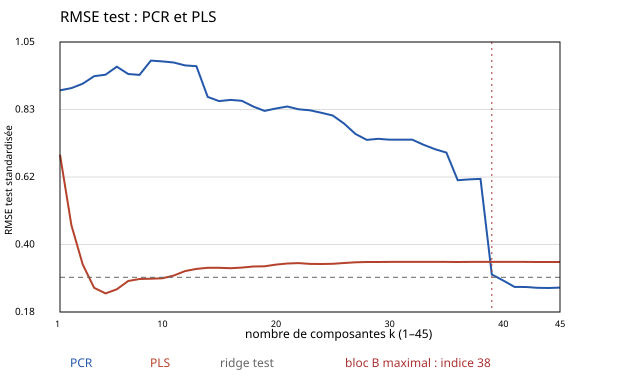

In [10]:
// Tracer les deux courbes sur les 45 valeurs de k et le meilleur ridge observé sur ce test.
display(new RegressionSvg(RegressionPlot(pcrErrors,plsErrors,ridgeErrors.Min(),maxBlockB)),"image/svg+xml");

### Lecture du résultat

À k = 5 : PCR 0.942 contre PLS 0.244 — **3.9× d'écart** pour le même budget de composantes. Les deux courbes convergent (≈ 0.26-0.28) quand k approche 45 : la PCR finit par engloutir le signal dans son budget ; la PLS l'a capturé d'emblée. La ligne rouge (indice 38, 39ᵉ composante) matérialise l'entrée du signal dans l'ordre des variances ; le trait pointillé (ridge optimal, 0.295) rappelle que la pénalisation seule se place entre les deux.


## 7. Sélection de k par validation croisée — la courbe qui choisit

En pratique on ne regarde pas le test pour choisir $k$ : on valide croisée **sur le train** (5 folds, même graine), et l'on trace la RMSEP de CV. Le $k$ retenu doit coïncider avec ce que la figure du §6 laissait espérer.


La standardisation de X et Y a été ajustée sur tout le train avant les plis : les estimations internes de CV comportent donc une fuite de prétraitement entre plis. Le test reste exclu. Pour une estimation sans cette fuite, placer les transformations dans chaque pipeline de validation.


In [11]:
// Choisir k par cinq plis sur le régime leurre et comparer les mêmes deux régimes.
var selection=SelectComponents(42);
int kPcr=selection.pcr;
int kPls=selection.pls;
Console.WriteLine($"CV : PCR k={kPcr}, RMSE={selection.pcrErrors.Min():F4} ; PLS k={kPls}, RMSE={selection.plsErrors.Min():F4}");

CV : PCR k=45, RMSE=0.3273 ; PLS k=7, RMSE=0.3085


### Lecture du résultat

La validation croisée — qui ne voit jamais le test — retient k = 45 pour la PCR et k = 7 pour la PLS, contre des optima test de 44 et 5 : les RMSE test aux k retenus (0.262 et 0.283) sont à peine au-dessus des minima. La sélection par CV retrouve donc bien le régime de chaque méthode. Noter le choix CV de la PCR : 45 composantes (plafond de la grille ; le rang mesuré vaut 119 et l'optimum hors grille est inconnu) — la CV « avale » les composantes de bruit parce qu'elles ne nuisent presque plus une fois le signal inclus, là où la PLS n'a besoin que de 7 composantes pour la même performance.


## 8. Scores, loadings — où chaque méthode met ses poids

Le diagnostic final compare les **loadings** (poids des variables) : la PLS concentre-t-elle sa première composante sur le bloc B, là où l'ACP la dépensait sur le bloc A ?


Part du bloc B en norme carrée : PCA=0.0289, PLS=0.6099.


Somme des poids absolus : PCA A=10.834, B=0.368 ; PLS A=7.033, B=1.746.


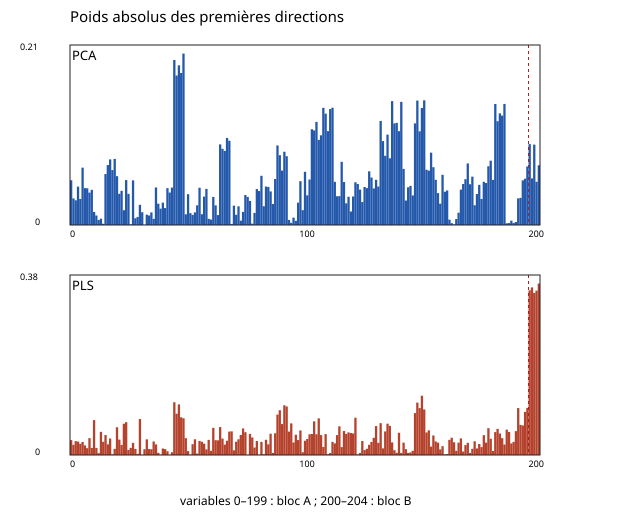

In [12]:
// Comparer les poids de la première direction PCA à ceux du premier axe PLS.
double[] plsWeights;
using (Py.GIL())
{
    py.Exec("pls_first=PLSRegression(n_components=1,scale=False).fit(Xtr,Ytr); weights_json=json.dumps(pls_first.x_weights_[:,0].tolist())");
    plsWeights=Vector(JsonDocument.Parse(py.Get("weights_json").As<string>()).RootElement);
}
double pcaSquared=components[0].Skip(200).Sum(v=>v*v);
double plsSquared=plsWeights.Skip(200).Sum(v=>v*v);
Console.WriteLine($"Part du bloc B en norme carrée : PCA={pcaSquared:F4}, PLS={plsSquared:F4}.");
double pcaA=components[0].Take(200).Sum(Math.Abs),pcaB=components[0].Skip(200).Sum(Math.Abs);
double plsA=plsWeights.Take(200).Sum(Math.Abs),plsB=plsWeights.Skip(200).Sum(Math.Abs);
Console.WriteLine($"Somme des poids absolus : PCA A={pcaA:F3}, B={pcaB:F3} ; PLS A={plsA:F3}, B={plsB:F3}.");
display(new RegressionSvg(LoadingPlot(components[0],plsWeights)),"image/svg+xml");

### Lecture du résultat

La première composante ACP répartit sa masse presque uniformément sur le bloc A (10.83 contre 0.37 sur le bloc B — les 200 variables du leurre). La première composante PLS concentre 1.75 de masse sur les 5 variables du signal, soit **20% de sa masse sur 2.4% des variables** — 8× leur part uniforme ; en norme carrée (la direction elle-même), la part du bloc B monte à 61%. Le w₁ garde néanmoins une composante sur le bloc A : la PLS maximise la *covariance*, qui récompense aussi les directions de forte variance de X — le tri par Cov n'est pas un tri par corrélation pure.


## 9. Comparaison finale — verdict par régime

Deux régimes, mêmes split et graine : le régime **leurre** (notre bloc A dominant en variance, signal en variance mineure) et un régime **aligné** où la cible vit cette fois dans les directions de variance dominante (une combinaison des facteurs du bloc A). La conclusion n'est pas « PLS gagne toujours » mais un verdict conditionné.


Les quantités `facteurs_A` du code sont des proxies construits à partir de variables observées, et non les facteurs latents exacts du générateur. Les valeurs `k` obtenues sur le régime leurre sont réutilisées pour le régime aligné : le second régime ne bénéficie pas d’une sélection indépendante de `k`.


In [13]:
// Comparer les deux régimes en réutilisant les k retenus sur le leurre.
using (Py.GIL())
{
    // L'alignement utilise les proxies observés du bloc A et le même bruit.
    py.Exec(@"factors=np.array([[np.sqrt(.8)*X[i,g*5] for g in range(40)] for i in range(160)])
weights=rng.standard_normal(40)/np.sqrt(40)
Ya=factors@weights*3.+noise
Ya_mean,Ya_std=Ya[itr].mean(),Ya[itr].std()
Ya_tr,Ya_te=(Ya[itr]-Ya_mean)/Ya_std,(Ya[ite]-Ya_mean)/Ya_std");
}
var methods=new[] { "OLS", "RidgeCV", "PCR", "PLS" };
void PrintRegime(string regime,int pcrComponents,int plsComponents)
{
    Console.WriteLine($"Régime {regime} :");
    foreach(string method in methods)
    {
        int k=method=="PCR" ? pcrComponents : method=="PLS" ? plsComponents : 1;
        var result=FitAndPredict(method,k,regime);
        Console.WriteLine($"{method,-10} RMSE test={Rmse(result.truth,result.prediction):F4}");
    }
}
PrintRegime("leurre",kPcr,kPls);
PrintRegime("aligne",kPcr,kPls);

Régime leurre :


OLS        RMSE test=0.3441


RidgeCV    RMSE test=0.3160


PCR        RMSE test=0.2623


PLS        RMSE test=0.2834


Régime aligne :


OLS        RMSE test=0.6050


RidgeCV    RMSE test=0.4954


PCR        RMSE test=0.5804


PLS        RMSE test=0.5452


### Lecture du résultat

**Régime leurre** (cible dans une direction de faible variance) : PCR k=45 0.262 < PLS k=7 0.283 < ridge 0.316 < OLS 0.344 — les réductions de dimension dominent, et la PLS est la plus économe (7 composantes contre 45 pour les choix CV ; les minima test rétrospectifs utilisent 5 et 44). **Régime aligné** (cible dans les directions dominantes) : ridge 0.495 < PLS 0.545 < PCR 0.580 < OLS 0.605 — la pénalisation seule suffit et gagne. Le verdict est conditionné : *aucune méthode ne domine dans tous les régimes* ; c'est la position de la cible dans la hiérarchie des variances qui décide — et c'est précisément ce que la PLS découvre automatiquement en triant par Cov(Y, ·).


### Exercice 3 — votre propre régime

Construisez un régime où **PCR et PLS sont équivalents** : une cible alignée sur la première composante principale. Complétez `regime_equivalent` qui génère ce Y, refait le split et retourne les RMSEP de PCR k=3 et PLS k=3. *Indice : `Y = X_s @ comps[0]` (à la bonne échelle) est exactement la première composante — variance maximale et cible confondues.*


In [14]:
(double? pcr,double? pls) AlignedRegime(double[][] x,double[][] weights,int[] train,int[] test)
{
    // TODO : standardiser sur train, créer la cible alignée, ajuster PCR et PLS à k=3, renvoyer deux RMSE test.
    return (null,null);
}
JsonElement alignedData;
using (Py.GIL())
{
    py.Exec(@"exercise_rng=np.random.default_rng(192)
small_X=exercise_rng.normal(size=(40,5))
aligned_json=json.dumps(dict(X=X.tolist(),comps=pca_full.components_.tolist(),train=itr.tolist(),test=ite.tolist(),small=small_X.tolist()))");
    alignedData=JsonDocument.Parse(py.Get("aligned_json").As<string>()).RootElement;
}
var smallMatrix=Matrix(alignedData.GetProperty("small"));
var smallIdentity=Enumerable.Range(0,5).Select(i=>Enumerable.Range(0,5).Select(j=>i==j ? 1.0 : 0.0).ToArray()).ToArray();
var alignedFixtures=new[]
{
    (Matrix(alignedData.GetProperty("X")),Matrix(alignedData.GetProperty("comps")),ReadInts(alignedData.GetProperty("train")),ReadInts(alignedData.GetProperty("test"))),
    (smallMatrix,smallIdentity,Enumerable.Range(0,30).ToArray(),Enumerable.Range(30,10).ToArray())
};
var alignedAnswers=alignedFixtures.Select(f=>AlignedRegime(f.Item1,f.Item2,f.Item3,f.Item4)).ToArray();
if(alignedAnswers.All(a=>a.pcr==null && a.pls==null))
{
    Console.WriteLine("Exercice 3 à compléter.");
}
else if(alignedAnswers.Any(a=>a.pcr==null || a.pls==null))
{
    Console.WriteLine("Exercice 3 : à revoir");
}
else
{
    bool ok=true;
    for(int i=0;i<alignedFixtures.Length;i++)
    {
        var (x,weights,train,test)=alignedFixtures[i];
        double[] truth,pcrPrediction,plsPrediction;
        using (Py.GIL())
        {
            py.Set("ex_x",new PyString(JsonSerializer.Serialize(x)));
            py.Set("ex_w",new PyString(JsonSerializer.Serialize(weights)));
            py.Set("ex_tr",new PyString(JsonSerializer.Serialize(train)));
            py.Set("ex_te",new PyString(JsonSerializer.Serialize(test)));
            // L'oracle refait séparément les deux vrais estimateurs sur les données fournies.
            py.Exec(@"exx=np.asarray(json.loads(ex_x));exw=np.asarray(json.loads(ex_w));extrain=np.asarray(json.loads(ex_tr));extest=np.asarray(json.loads(ex_te))
exmu,exsd=exx[extrain].mean(axis=0),exx[extrain].std(axis=0)
exs=(exx-exmu)/exsd
exy=exs@exw[0]
exy=(exy-exy[extrain].mean())/exy[extrain].std()
exp=make_pipeline(PCA(n_components=3),LinearRegression()).fit(exs[extrain],exy[extrain])
exq=PLSRegression(n_components=3,scale=False).fit(exs[extrain],exy[extrain])
ex_json=json.dumps(dict(truth=exy[extest].tolist(),pcr=exp.predict(exs[extest]).tolist(),pls=exq.predict(exs[extest]).reshape(-1).tolist()))");
            var result=JsonDocument.Parse(py.Get("ex_json").As<string>()).RootElement;
            truth=Vector(result.GetProperty("truth"));
            pcrPrediction=Vector(result.GetProperty("pcr"));
            plsPrediction=Vector(result.GetProperty("pls"));
        }
        ok=ok && double.IsFinite(alignedAnswers[i].pcr.Value) && double.IsFinite(alignedAnswers[i].pls.Value)
            && Math.Abs(alignedAnswers[i].pcr.Value-Rmse(truth,pcrPrediction))<1e-9
            && Math.Abs(alignedAnswers[i].pls.Value-Rmse(truth,plsPrediction))<1e-9;
    }
    Console.WriteLine(ok ? "Exercice 3 : mesures cohérentes ; interpréter le régime" : "Exercice 3 : à revoir");
}

Exercice 3 à compléter.


## 9bis. Robustesse — le verdict sur dix graines

Un verdict sur un seul tirage peut flatter une méthode. La robustesse demande de **redessiner chaque graine** : données, bruit, découpage train/test, folds de CV, hyperparamètres — $\lambda$ par `RidgeCV` et $k$ par CV sont **re-choisis à l'intérieur de chaque graine**, sans réutiliser quoi que ce soit du tirage de la section 1. Dix graines, les deux régimes de la section 9, moyenne ± écart-type du RMSE test.

Pour chaque graine, les `k` sont sélectionnés sur le régime leurre puis réutilisés pour le régime aligné ; ils ne sont pas réajustés séparément pour ce dernier. Comme plus haut, la standardisation globale du train précède les plis internes.


In [15]:
// Pour chaque graine, régénérer données et plis ; k du leurre est réutilisé sur l'aligné.
var seeds=new[] { 0,1,2,3,7,11,21,42,99,123 };
var measured=new Dictionary<string,List<double>>();
foreach(string regime in new[] { "leurre", "aligne" })
{
    foreach(string method in methods)
    {
        measured[$"{regime}:{method}"]=new List<double>();
    }
}
var pcrSelections=new List<int>();
var plsSelections=new List<int>();
foreach(int seed in seeds)
{
    using (Py.GIL())
    {
        py.Set("seed",new PyInt(seed));
        py.Exec("Xtr,Xte,Ytr,Yte,Ya_tr,Ya_te=robust_data(int(seed))");
    }
    // 45 composantes × 5 plis × 2 méthodes, soit 450 fits par graine.
    var selected=SelectComponents(seed);
    pcrSelections.Add(selected.pcr);
    plsSelections.Add(selected.pls);
    foreach(string regime in new[] { "leurre", "aligne" })
    {
        foreach(string method in methods)
        {
            int k=method=="PCR" ? selected.pcr : method=="PLS" ? selected.pls : 1;
            var result=FitAndPredict(method,k,regime);
            measured[$"{regime}:{method}"].Add(Rmse(result.truth,result.prediction));
        }
    }
}
foreach(string method in methods)
{
    var a=measured[$"leurre:{method}"];
    var b=measured[$"aligne:{method}"];
    double ma=a.Average(),mb=b.Average();
    double sa=Math.Sqrt(a.Average(v=>Math.Pow(v-ma,2)));
    double sb=Math.Sqrt(b.Average(v=>Math.Pow(v-mb,2)));
    Console.WriteLine($"{method,-10} leurre={ma:F3} ± {sa:F3} ; aligné={mb:F3} ± {sb:F3}");
}
Console.WriteLine($"k retenus : PCR {pcrSelections.Min()}–{pcrSelections.Max()}, PLS {plsSelections.Min()}–{plsSelections.Max()}");
// Compter les égalités éventuelles dans le nombre de dernières places.
foreach(string regime in new[] { "leurre", "aligne" })
{
    int last=Enumerable.Range(0,seeds.Length).Count(i=>measured[$"{regime}:OLS"][i]>=methods.Max(method=>measured[$"{regime}:{method}"][i]));
    Console.WriteLine($"OLS dernière ou ex æquo : {last}/10 graines ({regime})");
}


OLS        leurre=0.307 ± 0.037 ; aligné=0.668 ± 0.129


RidgeCV    leurre=0.285 ± 0.030 ; aligné=0.600 ± 0.072


PCR        leurre=0.271 ± 0.042 ; aligné=0.643 ± 0.059


PLS        leurre=0.264 ± 0.036 ; aligné=0.612 ± 0.093


k retenus : PCR 42–45, PLS 6–10


OLS dernière ou ex æquo : 8/10 graines (leurre)


OLS dernière ou ex æquo : 6/10 graines (aligne)


### Lecture du résultat

Sur ces dix graines, les sorties comptent les cas où OLS min-norme est dernière ou ex æquo : dernière ou ex æquo **8 fois sur 10 dans le régime leurre**, **6 fois sur 10 dans le régime aligné**. Les moyennes disent le reste :

- **Régime leurre** : la PLS mène ($0{,}264 \pm 0{,}036$), juste devant la PCR ($0{,}271 \pm 0{,}042$) — quand le signal vit hors des directions de grande variance, les composantes qui regardent la cible restent le bon geste. L'écart moyen avec OLS ($0{,}307 \pm 0{,}037$) est modeste mais systématique.
- **Régime aligné** : le ridge mène ($0{,}600 \pm 0{,}072$) — quand le signal s'aligne sur la variance dominante, la pénalité suffit, et payer des composantes (PCR $0{,}643 \pm 0{,}059$) n'apporte rien. C'est aussi le régime où l'écart-type d'OLS s'envole ($\pm 0{,}129$) : la min-norme présente ici une dispersion notable selon le tirage.
- **Les $k$ retenus varient avec la graine** : la PLS reste parcimonieuse (6 à 10 composantes), la PCR CV ne trouve pas de coude net et reste au plafond de la grille (42 à 45 sur 45) — un $k$ « choisi » à la limite haute est un signal à lire, pas un nombre à citer.

Dix graines, deux régimes, hyperparamètres re-choisis à chaque tirage : les moyennes observées diffèrent selon le régime ; ces dix tirages ne garantissent pas un ordre identique pour chaque graine ni une loi universelle.

## 10. Exercices

Les trois exercices sont distribués après les sections ridge, PCR et comparaison des régimes. Les gardes contrôlent les quantités calculables ; les interprétations restent à discuter.


## À retenir

Trois réponses au même régime p > n : **ridge** rend le problème déterminé (X^⊤X + λI inversible pour tout λ > 0) mais reste une régression sur *toutes* les directions ; **PCR** réduit sur des composantes choisies sans regarder Y — efficace quand la cible vit dans les variances dominantes, dispendieuse (44 composantes ici) quand elle s'y cache ; **PLS** trie les directions par covariance avec la cible et trouve le signal en 5 composantes. La leçon transférable : *la variance d'une direction ne suffit pas à établir sa valeur prédictive* — Cov(Y, Xu) et Var(Xu) sont deux classements différents, et l'écart entre les deux est exploitable.

En pratique : commencer par `RidgeCV` (un seul hyperparamètre, robuste) ; passer à la PLS quand p > n est extrême ou quand l'interprétation par composantes (loadings) a de la valeur ; la PCR reste pertinente quand les composantes principales ont un sens métier propre. C'est aussi le geste du pipeline QuantConnect du cours ([ML-Training-Pipeline](../../../QuantConnect/ML-Training-Pipeline/README.md)), où la régression ridge régularise les prédictions en présence de caractéristiques nombreuses et corrélées — sans re-développer ici de cas trading.


| Concept | Mesure dans ce carnet |
|---|---|
| Le régime, posé | `n_train = 120`, `n_test = 40`, `p = 205` (`p/n = 1.71`) ; `R²` du modèle vrai `0.966` ; plancher de bruit `≈ 0.181` |
| OLS n'est pas mauvais, il est indéterminé | `rang(X) = 119` sur `205` colonnes : `86` directions du noyau de X_train, donc coefficients non identifiables sur ce train ; RMSE train `0.0000`, test `0.3441` (1,9 fois le bruit) |
| Ridge rend le problème déterminé | `λ CV = 3.1623` : RMSE test `0.3160` ; le balayage va de `0.344` (λ=1e-3) au minimum `0.295` de cette grille test, puis `0.722` (λ=1e3) |
| PCR paie son aveuglement | meilleur `k = 44` pour `0.2611` ; à `k=5` elle vaut encore `0.9418` : le signal n'entre vraiment qu'à la composante d’indice 38 (rang 39) |
| PLS regarde la cible | meilleur `k = 5` pour `0.2440` ; à budget égal (`k=5`), PCR est `3.9` fois moins bonne |
| La CV choisit à côté, mais honnêtement | k retenus `PCR 45` / `PLS 7` contre optimaux de test `44` / `5` ; RMSE au k choisi : `0.2623` / `0.2834` |
| Le verdict dépend du régime | régime leurre : OLS `0.3441` ; régime aligné : OLS `0.6050` — et sur dix graines, `0.307 ± 0.037` contre `0.668 ± 0.129` |

**La leçon transférable.** La variance d'une direction ne suffit pas à établir sa valeur prédictive : `Cov(Y, Xu)` et `Var(Xu)` sont deux classements différents, et l'écart entre les deux est exploitable. En pratique : commencer par `RidgeCV` (un hyperparamètre, robuste), passer à la PLS quand `p > n` est extrême ou quand les composantes ont valeur d'interprétation.

**Transition.** Le carnet suivant, [2.3d-Modele-Gaussien-LDA-QDA](2.3d-Modele-Gaussien-LDA-QDA.ipynb), revient à la classification et montre une autre hypothèse structurante : la forme des covariances de classes, qui décide de la frontière.

## Vérifiez votre compréhension

**1. `rang(X_train) = 119` sur 205 colonnes, et pourtant `RMSE train = 0.0000`. Pourquoi un ajustement parfait sur le train est-il ici la signature du problème, pas d'un bon modèle ?**

<details>
<summary>Réponse</summary>

Avec 120 observations centrées, l'espace des lignes n'a que 119 dimensions : le système est sous-déterminé, et la solution de norme minimale l'ajuste *exactement* — zéro résidu d'entraînement par construction. Les 86 directions du noyau ne modifient pas les prédictions sur X_train : les coefficients sont donc non identifiables sur ce train. Le rang établit cette indétermination ; le RMSE test (`0.3441`) en est une mesure distincte de généralisation, pas une preuve du rang.
</details>

**2. À `k=5` composantes, PCR affiche `0.9418` quand PLS affiche `0.2440`. D'où vient un écart aussi grand à budget égal ?**

<details>
<summary>Réponse</summary>

Les composantes PCA sont triées par variance expliquée, sans regarder `Y` : ici la 1re composante ne porte que `0.048` de la variance et `0.0289` seulement de la contribution du bloc signal — le signal entre massivement à la composante d’indice 38 (rang 39) (part `0.223`). La PLS trie ses directions par covariance avec la cible : sa première direction place déjà `20 %` de sa masse sur les 5 variables du signal. À `k=5`, l'une a presque tout le signal, l'autre presque rien.
</details>

**3. La validation croisée retient `k = 45` (PCR) et `k = 7` (PLS) alors que les optimaux de test sont `44` et `5`. La CV a-t-elle échoué ?**

<details>
<summary>Réponse</summary>

Non : elle a fait son travail, qui est de choisir *sans regarder le test*. Ses courbes sont plates autour de l'optimum (estimation sur 120 exemples), et le RMSE obtenu aux k retenus (`0.2623` / `0.2834`) reste proche des meilleurs (`0.2611` / `0.2440`). Exiger de la CV qu'elle devine l'argmax exact du test, c'est lui demander de lire le test — précisément ce qu'elle existe pour éviter.
</details>

## Pour aller plus loin

- [README de la sous-série 02-ML-Cours](README.md) — la carte des carnets et de leurs concepts-phares.
- [README de la série DataScienceWithAgents](../README.md) — le rôle de ce socle ML dans la formation.
- [2.3d-Modele-Gaussien-LDA-QDA](2.3d-Modele-Gaussien-LDA-QDA.ipynb) — la suite immédiate : le modèle gaussien et ses frontières.
- [2.6-Clustering-KMeans-PCA](2.6-Clustering-KMeans-PCA.ipynb) — l'ACP comme méthode en soi (structure sans étiquettes), ici utilisée comme simple prétraitement.
- [2.4-Arbres-Forets-Ensembles](2.4-Arbres-Forets-Ensembles.ipynb) — la réponse non paramétrique au même régime : des modèles qui ne postulent pas de forme linéaire.

## Références

- **Hoerl, A. E. & Kennard, R. W. (1970).** *Ridge regression: biased estimation for nonorthogonal problems.* Technometrics 12(1). La pénalité $\ell_2$ qui rend un problème mal conditionné déterminé.
- **Wold, H. (1975).** *Path models with latent variables: the NIPALS approach.* Dans Quantitative Sociology. L'algorithme qui extrait des composantes corrélées à la cible — le point de départ de la PLS.
- **de Jong, S. (1993).** *SIMPLS: an alternative approach to partial least squares regression.* Chemometrics and Intelligent Laboratory Systems 18(3). Une autre formulation de PLS ; `sklearn.cross_decomposition.PLSRegression` utilise NIPALS.
- **Frank, I. E. & Friedman, J. H. (1993).** *A statistical view of some chemometrics regression tools.* Technometrics 35(2). Pourquoi ridge, PCR et PLS forment un continuum de pénalisations, et quand chacune gagne.
- **Hastie, T., Tibshirani, R. & Friedman, J. (2009).** *The Elements of Statistical Learning*, §3.4-3.5. Le traitement de référence du régime $p > n$ et des estimateurs à rétrécissement.
- **Jolliffe, I. T. (2002).** *Principal Component Analysis*, 2e éd. La hiérarchie de variance que la PCR consomme — et perd quand le signal vit ailleurs.
- **Pedregosa, F. et al. (2011).** *Scikit-learn: machine learning in Python.* JMLR 12. `RidgeCV`, `PCA`, `PLSRegression`, `cross_val_predict`.
Les références bibliographiques sont reprises de la source versionnée du cours ; aucune lecture des publications n’est présumée pour la présente comparaison.
